In [1]:
%pip install -q requests tqdm pandas numpy matplotlib

Note: you may need to restart the kernel to use updated packages.


In [2]:
from pathlib import Path
from tqdm.auto import tqdm
import requests
import zipfile
import shutil
import hashlib
import json
import io
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path("/kaggle/working/building3d_tallinn")
ARCHIVE_DIR = ROOT / "archives"
PHASE1_DIR = ROOT / "phase1_outputs"

ARCHIVE_DIR.mkdir(parents=True, exist_ok=True)
PHASE1_DIR.mkdir(parents=True, exist_ok=True)

LOGIN_PAGE = "https://building3d.ucalgary.ca/login.php"
LOGIN_ACTION = "https://building3d.ucalgary.ca/assets/php/user.php"

URLS = {
    "building_pointclouds": "https://building3d.ucalgary.ca/assets/php/download.php?pointclouds",
    "roof_wireframes": "https://building3d.ucalgary.ca/assets/php/download.php?Tallinn",
    "meshes": "https://building3d.ucalgary.ca/assets/php/download.php?mesh"
}

ARCHIVES = {
    "building_pointclouds": ARCHIVE_DIR / "tallinn_building_pointclouds.zip",
    "roof_wireframes": ARCHIVE_DIR / "tallinn_roof_wireframes.zip",
    "meshes": ARCHIVE_DIR / "tallinn_meshes.zip"
}

print("Root:", ROOT)
print("Archives:", ARCHIVE_DIR)
print("Phase 1 outputs:", PHASE1_DIR)

Root: /kaggle/working/building3d_tallinn
Archives: /kaggle/working/building3d_tallinn/archives
Phase 1 outputs: /kaggle/working/building3d_tallinn/phase1_outputs


In [3]:
from kaggle_secrets import UserSecretsClient

user_secrets = UserSecretsClient()

secret_value_0 = user_secrets.get_secret("BUILDING3D_EMAIL")
secret_value_1 = user_secrets.get_secret("BUILDING3D_PASSWORD")

BUILDING3D_EMAIL = secret_value_0
BUILDING3D_PASSWORD = secret_value_1

assert BUILDING3D_EMAIL
assert BUILDING3D_PASSWORD

print("Building3D credentials loaded from Kaggle Secrets.")

Building3D credentials loaded from Kaggle Secrets.


In [4]:
def create_authenticated_session():
    active_session = requests.Session()

    active_session.headers.update({
        "User-Agent": "Mozilla/5.0",
        "Accept": "*/*",
        "Connection": "keep-alive"
    })

    login_page_response = active_session.get(
        LOGIN_PAGE,
        timeout=60
    )

    login_page_response.raise_for_status()

    login_response = active_session.post(
        LOGIN_ACTION,
        data={
            "email": BUILDING3D_EMAIL,
            "password": BUILDING3D_PASSWORD,
            "action": "login"
        },
        headers={
            "Referer": LOGIN_PAGE
        },
        allow_redirects=True,
        timeout=60
    )

    login_response.raise_for_status()

    probe_response = active_session.get(
        URLS["meshes"],
        stream=True,
        allow_redirects=True,
        timeout=(60, 120)
    )

    probe_type = probe_response.headers.get(
        "Content-Type",
        ""
    ).lower()

    probe_disposition = probe_response.headers.get(
        "Content-Disposition",
        ""
    ).lower()

    probe_url = probe_response.url.lower()
    probe_status = probe_response.status_code

    probe_response.close()

    valid_download = (
        probe_status in {200, 206}
        and "login.php" not in probe_url
        and "text/html" not in probe_type
        and (
            "zip" in probe_type
            or "attachment" in probe_disposition
            or ".zip" in probe_disposition
        )
    )

    assert valid_download, "Building3D authentication or download authorization failed."

    return active_session

session = create_authenticated_session()

print("Building3D authentication successful.")
print("Session cookies available:", len(session.cookies) > 0)

Building3D authentication successful.
Session cookies available: True


In [5]:
storage = shutil.disk_usage("/kaggle/working")

total_gib = storage.total / (1024 ** 3)
used_gib = storage.used / (1024 ** 3)
free_gib = storage.free / (1024 ** 3)

print("Total GiB:", round(total_gib, 2))
print("Used GiB:", round(used_gib, 2))
print("Free GiB:", round(free_gib, 2))

assert free_gib >= 8.5, "At least 8.5 GiB of free storage is required."

Total GiB: 19.52
Used GiB: 0.0
Free GiB: 19.5


In [6]:
def download_zip(url, destination, active_session, chunk_size=16 * 1024 * 1024):
    destination = Path(destination)

    if destination.exists() and zipfile.is_zipfile(destination):
        print("Already downloaded:", destination.name)
        print("Size GiB:", round(destination.stat().st_size / (1024 ** 3), 3))
        return destination

    existing_size = destination.stat().st_size if destination.exists() else 0
    request_headers = {}

    if existing_size > 0:
        request_headers["Range"] = f"bytes={existing_size}-"

    response = active_session.get(
        url,
        headers=request_headers,
        stream=True,
        allow_redirects=True,
        timeout=(60, 900)
    )

    response.raise_for_status()

    content_type = response.headers.get(
        "Content-Type",
        ""
    ).lower()

    content_disposition = response.headers.get(
        "Content-Disposition",
        ""
    ).lower()

    final_url = response.url.lower()

    invalid_response = (
        "login.php" in final_url
        or "text/html" in content_type
        or (
            "zip" not in content_type
            and "attachment" not in content_disposition
            and ".zip" not in content_disposition
        )
    )

    if invalid_response:
        response.close()
        raise RuntimeError("The server returned a login or HTML page instead of a ZIP archive.")

    if existing_size > 0 and response.status_code == 206:
        file_mode = "ab"
        progress_initial = existing_size
    else:
        file_mode = "wb"
        progress_initial = 0
        existing_size = 0

    response_size = int(
        response.headers.get("Content-Length", 0)
    )

    expected_total = (
        progress_initial + response_size
        if response_size > 0
        else None
    )

    with open(destination, file_mode) as destination_file:
        with tqdm(
            total=expected_total,
            initial=progress_initial,
            unit="B",
            unit_scale=True,
            unit_divisor=1024,
            desc=destination.name
        ) as progress:
            for data_chunk in response.iter_content(
                chunk_size=chunk_size
            ):
                if data_chunk:
                    destination_file.write(data_chunk)
                    progress.update(len(data_chunk))

    response.close()

    assert destination.exists()
    assert destination.stat().st_size > 0
    assert zipfile.is_zipfile(destination), f"{destination.name} is incomplete or invalid."

    print("Downloaded:", destination)
    print("Size GiB:", round(destination.stat().st_size / (1024 ** 3), 3))

    return destination

In [7]:
download_order = [
    "meshes",
    "roof_wireframes",
    "building_pointclouds"
]

for archive_name in download_order:
    try:
        download_zip(
            URLS[archive_name],
            ARCHIVES[archive_name],
            session
        )
    except RuntimeError:
        session = create_authenticated_session()
        download_zip(
            URLS[archive_name],
            ARCHIVES[archive_name],
            session
        )

print("All available Tallinn archives downloaded.")

tallinn_meshes.zip:   0%|          | 0.00/107M [00:00<?, ?B/s]

Downloaded: /kaggle/working/building3d_tallinn/archives/tallinn_meshes.zip
Size GiB: 0.105


tallinn_roof_wireframes.zip:   0%|          | 0.00/1.89G [00:00<?, ?B/s]

Downloaded: /kaggle/working/building3d_tallinn/archives/tallinn_roof_wireframes.zip
Size GiB: 1.885


tallinn_building_pointclouds.zip:   0%|          | 0.00/5.55G [00:00<?, ?B/s]

Downloaded: /kaggle/working/building3d_tallinn/archives/tallinn_building_pointclouds.zip
Size GiB: 5.552
All available Tallinn archives downloaded.


In [8]:
archive_inventory = []

for archive_name, archive_path in ARCHIVES.items():
    assert archive_path.exists()
    assert archive_path.stat().st_size > 0
    assert zipfile.is_zipfile(archive_path)

    with zipfile.ZipFile(archive_path, "r") as archive:
        members = [
            member
            for member in archive.infolist()
            if not member.is_dir()
        ]

        extension_counts = pd.Series(
            [
                Path(member.filename).suffix.lower()
                for member in members
            ]
        ).value_counts().to_dict()

        assert len(members) > 0

        archive_inventory.append({
            "archive": archive_name,
            "path": str(archive_path),
            "size_gib": archive_path.stat().st_size / (1024 ** 3),
            "member_count": len(members),
            "extensions": extension_counts
        })

archive_inventory_df = pd.DataFrame(
    archive_inventory
)

display(archive_inventory_df)

assert len(archive_inventory_df) == 3
assert archive_inventory_df["member_count"].min() > 0

,archive,path,size_gib,member_count,extensions
0,building_pointclouds,/kaggle/working/building3d_tallinn/archives/ta...,5.552077,47078,{'.xyz': 47078}
1,roof_wireframes,/kaggle/working/building3d_tallinn/archives/ta...,1.885344,68708,"{'.xyz': 36090, '.obj': 32618}"
2,meshes,/kaggle/working/building3d_tallinn/archives/ta...,0.104790,47079,{'.obj': 47079}


In [9]:
def canonical_building_id(member_name):
    return Path(member_name).stem.strip()

def detect_official_split(member_name):
    if member_name is None:
        return None

    path_parts = [
        part.lower()
        for part in Path(member_name).parts
    ]

    if any(part in {"train", "training"} for part in path_parts):
        return "train"

    if any(part in {"val", "valid", "validation"} for part in path_parts):
        return "val"

    if any(part in {"test", "testing"} for part in path_parts):
        return "test"

    return None

def create_member_index(archive_path, accepted_suffixes):
    accepted_suffixes = {
        suffix.lower()
        for suffix in accepted_suffixes
    }

    member_index = {}
    duplicate_ids = []

    with zipfile.ZipFile(archive_path, "r") as archive:
        for member_name in archive.namelist():
            if member_name.endswith("/"):
                continue

            member_suffix = Path(
                member_name
            ).suffix.lower()

            if member_suffix not in accepted_suffixes:
                continue

            building_id = canonical_building_id(
                member_name
            )

            if building_id in member_index:
                duplicate_ids.append(building_id)
            else:
                member_index[building_id] = member_name

    assert not duplicate_ids, f"Duplicate building IDs found: {duplicate_ids[:10]}"

    return member_index

building_pc_index = create_member_index(
    ARCHIVES["building_pointclouds"],
    {".xyz"}
)

roof_pc_index = create_member_index(
    ARCHIVES["roof_wireframes"],
    {".xyz"}
)

wireframe_index = create_member_index(
    ARCHIVES["roof_wireframes"],
    {".obj"}
)

mesh_index = create_member_index(
    ARCHIVES["meshes"],
    {".obj"}
)

print("Building point clouds:", len(building_pc_index))
print("Roof point clouds:", len(roof_pc_index))
print("Wireframes:", len(wireframe_index))
print("Meshes:", len(mesh_index))

Building point clouds: 47078
Roof point clouds: 36090
Wireframes: 32618
Meshes: 47079


In [10]:
all_building_ids = sorted(
    set(building_pc_index)
    | set(roof_pc_index)
    | set(wireframe_index)
    | set(mesh_index),
    key=lambda value: (
        not value.isdigit(),
        int(value) if value.isdigit() else value
    )
)

manifest_records = []

for building_id in all_building_ids:
    building_member = building_pc_index.get(
        building_id
    )

    roof_member = roof_pc_index.get(
        building_id
    )

    wireframe_member = wireframe_index.get(
        building_id
    )

    mesh_member = mesh_index.get(
        building_id
    )

    detected_splits = {
        split_name
        for split_name in [
            detect_official_split(building_member),
            detect_official_split(roof_member),
            detect_official_split(wireframe_member),
            detect_official_split(mesh_member)
        ]
        if split_name is not None
    }

    if len(detected_splits) == 1:
        official_split = next(
            iter(detected_splits)
        )
    elif len(detected_splits) > 1:
        official_split = "conflict"
    else:
        official_split = None

    manifest_records.append({
        "building_id": str(building_id),
        "building_pc_member": building_member,
        "roof_pc_member": roof_member,
        "wireframe_member": wireframe_member,
        "mesh_member": mesh_member,
        "has_building_pc": building_member is not None,
        "has_roof_pc": roof_member is not None,
        "has_wireframe": wireframe_member is not None,
        "has_mesh": mesh_member is not None,
        "official_split": official_split
    })

manifest = pd.DataFrame(
    manifest_records
)

manifest["has_core_pair"] = (
    manifest["has_building_pc"]
    & manifest["has_mesh"]
)

manifest["has_structural_pair"] = (
    manifest["has_building_pc"]
    & manifest["has_roof_pc"]
    & manifest["has_wireframe"]
    & manifest["has_mesh"]
)

display(manifest.head())

print("Manifest shape:", manifest.shape)

,building_id,building_pc_member,roof_pc_member,wireframe_member,mesh_member,has_building_pc,has_roof_pc,has_wireframe,has_mesh,official_split,has_core_pair,has_structural_pair
0,1,pointclouds/1.xyz,None,None,building_mesh/1.obj,True,False,False,True,None,True,False
1,2,pointclouds/2.xyz,Tallinn/train/xyz/2.xyz,Tallinn/train/wireframe/2.obj,building_mesh/2.obj,True,True,True,True,train,True,True
2,3,pointclouds/3.xyz,Tallinn/train/xyz/3.xyz,Tallinn/train/wireframe/3.obj,building_mesh/3.obj,True,True,True,True,train,True,True
3,4,pointclouds/4.xyz,Tallinn/test/xyz/4.xyz,None,building_mesh/4.obj,True,True,False,True,test,True,False
4,5,pointclouds/5.xyz,Tallinn/train/xyz/5.xyz,Tallinn/train/wireframe/5.obj,building_mesh/5.obj,True,True,True,True,train,True,True


Manifest shape: (47079, 12)


In [11]:
pairing_summary = pd.Series({
    "total_unique_ids": len(manifest),
    "building_pointcloud_ids": int(manifest["has_building_pc"].sum()),
    "roof_pointcloud_ids": int(manifest["has_roof_pc"].sum()),
    "wireframe_ids": int(manifest["has_wireframe"].sum()),
    "mesh_ids": int(manifest["has_mesh"].sum()),
    "core_pointcloud_mesh_pairs": int(manifest["has_core_pair"].sum()),
    "complete_structural_pairs": int(manifest["has_structural_pair"].sum()),
    "missing_building_pointcloud": int((~manifest["has_building_pc"]).sum()),
    "missing_roof_pointcloud": int((~manifest["has_roof_pc"]).sum()),
    "missing_wireframe": int((~manifest["has_wireframe"]).sum()),
    "missing_mesh": int((~manifest["has_mesh"]).sum())
})

display(
    pairing_summary.to_frame("count")
)

assert manifest["building_id"].is_unique
assert manifest["has_building_pc"].sum() > 1000
assert manifest["has_mesh"].sum() > 1000
assert manifest["has_core_pair"].sum() > 1000
assert manifest["has_structural_pair"].sum() > 1000

,count
total_unique_ids,47079
building_pointcloud_ids,47078
roof_pointcloud_ids,36090
wireframe_ids,32618
mesh_ids,47079
core_pointcloud_mesh_pairs,47078
complete_structural_pairs,32618
missing_building_pointcloud,1
missing_roof_pointcloud,10989
missing_wireframe,14461


In [12]:
def parse_xyz_bytes(file_bytes):
    file_text = file_bytes.decode(
        "utf-8",
        errors="ignore"
    )

    data_lines = [
        line.strip()
        for line in file_text.splitlines()
        if line.strip()
        and not line.lstrip().startswith("#")
    ]

    if not data_lines:
        return np.empty(
            (0, 0),
            dtype=np.float32
        )

    column_count = len(
        data_lines[0].split()
    )

    parsed_values = np.fromstring(
        "\n".join(data_lines),
        sep=" ",
        dtype=np.float64
    )

    if (
        column_count == 0
        or parsed_values.size % column_count != 0
    ):
        parsed_array = np.loadtxt(
            io.StringIO("\n".join(data_lines)),
            dtype=np.float64
        )

        parsed_array = np.atleast_2d(
            parsed_array
        )
    else:
        parsed_array = parsed_values.reshape(
            -1,
            column_count
        )

    return parsed_array.astype(
        np.float32
    )

def parse_obj_bytes(file_bytes):
    vertices = []
    edges = []
    faces = []

    file_text = file_bytes.decode(
        "utf-8",
        errors="ignore"
    )

    for raw_line in file_text.splitlines():
        tokens = raw_line.strip().split()

        if not tokens:
            continue

        if tokens[0] == "v" and len(tokens) >= 4:
            vertices.append([
                float(tokens[1]),
                float(tokens[2]),
                float(tokens[3])
            ])

        if tokens[0] == "l" and len(tokens) >= 3:
            indices = [
                int(token.split("/")[0])
                for token in tokens[1:]
            ]

            edges.extend([
                [
                    indices[index] - 1,
                    indices[index + 1] - 1
                ]
                for index in range(
                    len(indices) - 1
                )
            ])

        if tokens[0] == "f" and len(tokens) >= 4:
            face_indices = [
                int(token.split("/")[0]) - 1
                for token in tokens[1:]
            ]

            faces.append(
                np.asarray(
                    face_indices,
                    dtype=np.int64
                )
            )

    vertex_array = np.asarray(
        vertices,
        dtype=np.float32
    ).reshape(-1, 3)

    edge_array = np.asarray(
        edges,
        dtype=np.int64
    ).reshape(-1, 2)

    return vertex_array, edge_array, faces

def remove_nonfinite_rows(array):
    array = np.asarray(array)

    if array.ndim != 2 or len(array) == 0:
        return array

    return array[
        np.isfinite(array).all(axis=1)
    ]

def valid_edge_indices(edges, vertex_count):
    return bool(
        len(edges) > 0
        and vertex_count > 0
        and edges.min() >= 0
        and edges.max() < vertex_count
    )

def valid_face_indices(faces, vertex_count):
    if not faces or vertex_count == 0:
        return False

    all_indices = np.concatenate(
        faces
    )

    return bool(
        all_indices.size > 0
        and all_indices.min() >= 0
        and all_indices.max() < vertex_count
    )

def fraction_inside_bbox(vertices, minimum, maximum, padding=2.0):
    if len(vertices) == 0:
        return 0.0

    finite_mask = np.isfinite(
        vertices
    ).all(axis=1)

    if not finite_mask.all():
        return 0.0

    inside_mask = np.all(
        (vertices >= minimum - padding)
        & (vertices <= maximum + padding),
        axis=1
    )

    return float(
        inside_mask.mean()
    )

In [13]:
structural_candidates = manifest.loc[
    manifest["has_structural_pair"],
    "building_id"
].astype(str).tolist()

assert structural_candidates

sample_id = structural_candidates[0]

sample_row = manifest.set_index(
    "building_id"
).loc[sample_id]

with zipfile.ZipFile(
    ARCHIVES["building_pointclouds"],
    "r"
) as building_archive:
    sample_building = parse_xyz_bytes(
        building_archive.read(
            sample_row["building_pc_member"]
        )
    )

with zipfile.ZipFile(
    ARCHIVES["roof_wireframes"],
    "r"
) as roof_archive:
    sample_roof = parse_xyz_bytes(
        roof_archive.read(
            sample_row["roof_pc_member"]
        )
    )

    sample_wireframe_vertices, sample_wireframe_edges, sample_wireframe_faces = parse_obj_bytes(
        roof_archive.read(
            sample_row["wireframe_member"]
        )
    )

with zipfile.ZipFile(
    ARCHIVES["meshes"],
    "r"
) as mesh_archive:
    sample_mesh_vertices, sample_mesh_edges, sample_mesh_faces = parse_obj_bytes(
        mesh_archive.read(
            sample_row["mesh_member"]
        )
    )

print("Building ID:", sample_id)
print("Building point cloud:", sample_building.shape)
print("Roof point cloud:", sample_roof.shape)
print("Wireframe vertices:", sample_wireframe_vertices.shape)
print("Wireframe edges:", sample_wireframe_edges.shape)
print("Mesh vertices:", sample_mesh_vertices.shape)
print("Mesh faces:", len(sample_mesh_faces))

assert sample_building.ndim == 2
assert sample_building.shape[1] >= 3
assert sample_roof.ndim == 2
assert sample_roof.shape[1] >= 3
assert len(sample_building) > 0
assert len(sample_roof) > 0
assert len(sample_wireframe_vertices) >= 3
assert len(sample_wireframe_edges) >= 1
assert len(sample_mesh_vertices) >= 3
assert len(sample_mesh_faces) >= 1

Building ID: 2
Building point cloud: (5083, 8)
Roof point cloud: (4683, 8)
Wireframe vertices: (8, 3)
Wireframe edges: (8, 2)
Mesh vertices: (18, 3)
Mesh faces: 32


In [14]:
quality_path = PHASE1_DIR / "quality_metadata.csv"

if quality_path.exists():
    previous_quality = pd.read_csv(
        quality_path,
        dtype={
            "building_id": str
        }
    )

    quality_records = previous_quality.to_dict(
        "records"
    )

    completed_ids = set(
        previous_quality["building_id"].astype(str)
    )
else:
    quality_records = []
    completed_ids = set()

scan_manifest = manifest[
    manifest["has_core_pair"]
].copy()

scan_manifest["building_id"] = scan_manifest[
    "building_id"
].astype(str)

scan_manifest = scan_manifest[
    ~scan_manifest["building_id"].isin(
        completed_ids
    )
]

new_record_count = 0

with zipfile.ZipFile(
    ARCHIVES["building_pointclouds"],
    "r"
) as building_archive, zipfile.ZipFile(
    ARCHIVES["roof_wireframes"],
    "r"
) as roof_archive, zipfile.ZipFile(
    ARCHIVES["meshes"],
    "r"
) as mesh_archive:

    for row in tqdm(
        scan_manifest.itertuples(index=False),
        total=len(scan_manifest),
        desc="Tallinn quality scan"
    ):
        try:
            building_array = parse_xyz_bytes(
                building_archive.read(
                    row.building_pc_member
                )
            )

            original_building_rows = len(
                building_array
            )

            building_array = remove_nonfinite_rows(
                building_array
            )

            building_xyz = building_array[:, :3]

            mesh_vertices, mesh_edges, mesh_faces = parse_obj_bytes(
                mesh_archive.read(
                    row.mesh_member
                )
            )

            if row.has_roof_pc:
                roof_array = parse_xyz_bytes(
                    roof_archive.read(
                        row.roof_pc_member
                    )
                )

                original_roof_rows = len(
                    roof_array
                )

                roof_array = remove_nonfinite_rows(
                    roof_array
                )

                roof_xyz = roof_array[:, :3]
            else:
                original_roof_rows = 0
                roof_array = np.empty(
                    (0, 0),
                    dtype=np.float32
                )

                roof_xyz = np.empty(
                    (0, 3),
                    dtype=np.float32
                )

            if row.has_wireframe:
                wireframe_vertices, wireframe_edges, wireframe_faces = parse_obj_bytes(
                    roof_archive.read(
                        row.wireframe_member
                    )
                )
            else:
                wireframe_vertices = np.empty(
                    (0, 3),
                    dtype=np.float32
                )

                wireframe_edges = np.empty(
                    (0, 2),
                    dtype=np.int64
                )

            building_center = building_xyz.mean(
                axis=0
            )

            building_distances = np.linalg.norm(
                building_xyz - building_center,
                axis=1
            )

            building_scale = float(
                building_distances.max()
            )

            bbox_minimum = building_xyz.min(
                axis=0
            )

            bbox_maximum = building_xyz.max(
                axis=0
            )

            mesh_indices_valid = valid_face_indices(
                mesh_faces,
                len(mesh_vertices)
            )

            mesh_inside_fraction = fraction_inside_bbox(
                mesh_vertices,
                bbox_minimum,
                bbox_maximum,
                padding=2.0
            )

            wireframe_indices_valid = valid_edge_indices(
                wireframe_edges,
                len(wireframe_vertices)
            )

            wireframe_inside_fraction = fraction_inside_bbox(
                wireframe_vertices,
                bbox_minimum,
                bbox_maximum,
                padding=2.0
            )

            roof_inside_fraction = fraction_inside_bbox(
                roof_xyz,
                bbox_minimum,
                bbox_maximum,
                padding=2.0
            )

            core_structural_valid = bool(
                len(building_xyz) >= 10
                and building_array.shape[1] >= 3
                and len(mesh_vertices) >= 3
                and len(mesh_faces) >= 1
                and np.isfinite(building_xyz).all()
                and np.isfinite(mesh_vertices).all()
                and np.isfinite(building_center).all()
                and np.isfinite(building_scale)
                and building_scale > 0
                and mesh_indices_valid
            )

            core_alignment_valid = bool(
                mesh_inside_fraction >= 0.90
            )

            phase1_core_valid = bool(
                core_structural_valid
                and core_alignment_valid
            )

            structural_modalities_valid = bool(
                row.has_roof_pc
                and row.has_wireframe
                and len(roof_xyz) >= 10
                and roof_array.shape[1] >= 3
                and len(wireframe_vertices) >= 3
                and len(wireframe_edges) >= 1
                and np.isfinite(roof_xyz).all()
                and np.isfinite(wireframe_vertices).all()
                and wireframe_indices_valid
            )

            structural_alignment_valid = bool(
                roof_inside_fraction >= 0.90
                and wireframe_inside_fraction >= 0.90
            )

            phase1_structural_valid = bool(
                phase1_core_valid
                and structural_modalities_valid
                and structural_alignment_valid
            )

            quality_records.append({
                "building_id": str(row.building_id),
                "building_rows": int(len(building_array)),
                "building_columns": int(building_array.shape[1]),
                "removed_building_rows": int(original_building_rows - len(building_array)),
                "roof_rows": int(len(roof_array)),
                "roof_columns": int(roof_array.shape[1]) if roof_array.ndim == 2 else 0,
                "removed_roof_rows": int(original_roof_rows - len(roof_array)),
                "wireframe_vertices": int(len(wireframe_vertices)),
                "wireframe_edges": int(len(wireframe_edges)),
                "mesh_vertices": int(len(mesh_vertices)),
                "mesh_faces": int(len(mesh_faces)),
                "center_x": float(building_center[0]),
                "center_y": float(building_center[1]),
                "center_z": float(building_center[2]),
                "scale": building_scale,
                "bbox_min_x": float(bbox_minimum[0]),
                "bbox_min_y": float(bbox_minimum[1]),
                "bbox_min_z": float(bbox_minimum[2]),
                "bbox_max_x": float(bbox_maximum[0]),
                "bbox_max_y": float(bbox_maximum[1]),
                "bbox_max_z": float(bbox_maximum[2]),
                "roof_inside_fraction": roof_inside_fraction,
                "wireframe_inside_fraction": wireframe_inside_fraction,
                "mesh_inside_fraction": mesh_inside_fraction,
                "wireframe_indices_valid": wireframe_indices_valid,
                "mesh_indices_valid": mesh_indices_valid,
                "phase1_core_valid": phase1_core_valid,
                "phase1_structural_valid": phase1_structural_valid,
                "error": ""
            })

        except Exception as exception:
            quality_records.append({
                "building_id": str(row.building_id),
                "building_rows": 0,
                "building_columns": 0,
                "removed_building_rows": 0,
                "roof_rows": 0,
                "roof_columns": 0,
                "removed_roof_rows": 0,
                "wireframe_vertices": 0,
                "wireframe_edges": 0,
                "mesh_vertices": 0,
                "mesh_faces": 0,
                "center_x": np.nan,
                "center_y": np.nan,
                "center_z": np.nan,
                "scale": np.nan,
                "bbox_min_x": np.nan,
                "bbox_min_y": np.nan,
                "bbox_min_z": np.nan,
                "bbox_max_x": np.nan,
                "bbox_max_y": np.nan,
                "bbox_max_z": np.nan,
                "roof_inside_fraction": 0.0,
                "wireframe_inside_fraction": 0.0,
                "mesh_inside_fraction": 0.0,
                "wireframe_indices_valid": False,
                "mesh_indices_valid": False,
                "phase1_core_valid": False,
                "phase1_structural_valid": False,
                "error": str(exception)
            })

        new_record_count += 1

        if new_record_count % 250 == 0:
            pd.DataFrame(
                quality_records
            ).to_csv(
                quality_path,
                index=False
            )

quality = pd.DataFrame(
    quality_records
)

quality = quality.drop_duplicates(
    subset="building_id",
    keep="last"
).sort_values(
    "building_id"
)

quality.to_csv(
    quality_path,
    index=False
)

print("Scanned buildings:", len(quality))
print("Valid point-cloud/mesh pairs:", int(quality["phase1_core_valid"].sum()))
print("Valid complete structural pairs:", int(quality["phase1_structural_valid"].sum()))

Tallinn quality scan:   0%|          | 0/47078 [00:00<?, ?it/s]

Scanned buildings: 47078
Valid point-cloud/mesh pairs: 46123
Valid complete structural pairs: 32014


In [15]:
quality_boolean_columns = [
    "wireframe_indices_valid",
    "mesh_indices_valid",
    "phase1_core_valid",
    "phase1_structural_valid"
]

for column_name in quality_boolean_columns:
    quality[column_name] = quality[
        column_name
    ].fillna(False).astype(bool)

quality_summary = pd.Series({
    "scanned_buildings": len(quality),
    "valid_core_pairs": int(quality["phase1_core_valid"].sum()),
    "invalid_core_pairs": int((~quality["phase1_core_valid"]).sum()),
    "valid_structural_pairs": int(quality["phase1_structural_valid"].sum()),
    "records_with_errors": int(quality["error"].fillna("").ne("").sum())
})

display(
    quality_summary.to_frame("count")
)

display(
    quality.loc[
        ~quality["phase1_core_valid"],
        [
            "building_id",
            "building_rows",
            "mesh_vertices",
            "mesh_faces",
            "mesh_inside_fraction",
            "error"
        ]
    ].head(20)
)

assert quality["building_id"].is_unique
assert quality["phase1_core_valid"].sum() > 1000
assert quality.loc[
    quality["phase1_core_valid"],
    "scale"
].gt(0).all()

,count
scanned_buildings,47078
valid_core_pairs,46123
invalid_core_pairs,955
valid_structural_pairs,32014
records_with_errors,0


,building_id,building_rows,mesh_vertices,mesh_faces,mesh_inside_fraction,error
10019,10020,1649,16,28,0.312500,
10063,10064,615,8,12,0.750000,
10131,10132,210,10,16,0.500000,
10214,10215,496,43,78,0.883721,
10578,10579,160,68,132,0.073529,
10611,10612,2766,26,48,0.692308,
1061,1062,17491,12,20,0.583333,
1074,1075,1389,8,12,0.500000,
10785,10786,1162,19,34,0.789474,
10806,10807,3774,24,41,0.875000,


In [16]:
manifest["building_id"] = manifest[
    "building_id"
].astype(str)

quality["building_id"] = quality[
    "building_id"
].astype(str)

phase1_manifest = manifest.merge(
    quality,
    on="building_id",
    how="left"
)

manifest_boolean_columns = [
    "has_building_pc",
    "has_roof_pc",
    "has_wireframe",
    "has_mesh",
    "has_core_pair",
    "has_structural_pair",
    "wireframe_indices_valid",
    "mesh_indices_valid",
    "phase1_core_valid",
    "phase1_structural_valid"
]

for column_name in manifest_boolean_columns:
    phase1_manifest[column_name] = phase1_manifest[
        column_name
    ].fillna(False).astype(bool)

print("Total IDs:", len(phase1_manifest))
print("Core pairs:", int(phase1_manifest["has_core_pair"].sum()))
print("Valid core pairs:", int(phase1_manifest["phase1_core_valid"].sum()))
print("Valid structural pairs:", int(phase1_manifest["phase1_structural_valid"].sum()))

assert phase1_manifest["building_id"].is_unique
assert phase1_manifest["phase1_core_valid"].sum() > 1000

Total IDs: 47079
Core pairs: 47078
Valid core pairs: 46123
Valid structural pairs: 32014


/tmp/ipykernel_58/1726968111.py:31: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  ].fillna(False).astype(bool)
/tmp/ipykernel_58/1726968111.py:31: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  ].fillna(False).astype(bool)
/tmp/ipykernel_58/1726968111.py:31: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  ].fillna(False).astype(bool)
/tmp/ip

In [17]:
def deterministic_split(building_id):
    hexadecimal_digest = hashlib.sha256(
        str(building_id).encode("utf-8")
    ).hexdigest()

    split_value = int(
        hexadecimal_digest[:16],
        16
    ) / float(16 ** 16)

    if split_value < 0.80:
        return "train"

    if split_value < 0.90:
        return "val"

    return "test"

phase1_manifest["project_split"] = "excluded"

valid_core_mask = phase1_manifest[
    "phase1_core_valid"
]

phase1_manifest.loc[
    valid_core_mask,
    "project_split"
] = phase1_manifest.loc[
    valid_core_mask,
    "building_id"
].map(
    deterministic_split
)

split_counts = phase1_manifest.loc[
    valid_core_mask,
    "project_split"
].value_counts()

display(
    split_counts.to_frame("count")
)

assert set(split_counts.index) == {
    "train",
    "val",
    "test"
}

assert split_counts.min() > 0

assert phase1_manifest.loc[
    valid_core_mask,
    "project_split"
].ne("excluded").all()

assert phase1_manifest.loc[
    ~valid_core_mask,
    "project_split"
].eq("excluded").all()

,count
project_split,
train,36819
test,4659
val,4645


In [18]:
valid_core_manifest = phase1_manifest[
    phase1_manifest["phase1_core_valid"]
].copy()

valid_structural_manifest = phase1_manifest[
    phase1_manifest["phase1_structural_valid"]
].copy()

invalid_manifest = phase1_manifest[
    ~phase1_manifest["phase1_core_valid"]
].copy()

phase1_manifest.to_csv(
    PHASE1_DIR / "manifest_all.csv",
    index=False
)

valid_core_manifest.to_csv(
    PHASE1_DIR / "manifest_core_valid.csv",
    index=False
)

valid_structural_manifest.to_csv(
    PHASE1_DIR / "manifest_structural_valid.csv",
    index=False
)

invalid_manifest.to_csv(
    PHASE1_DIR / "invalid_samples.csv",
    index=False
)

for split_name in [
    "train",
    "val",
    "test"
]:
    split_building_ids = valid_core_manifest.loc[
        valid_core_manifest["project_split"] == split_name,
        "building_id"
    ].astype(str)

    split_building_ids.to_csv(
        PHASE1_DIR / f"{split_name}_ids.txt",
        index=False,
        header=False
    )

configuration = {
    "dataset": "Building3D Tallinn",
    "project_phase": "Phase 1",
    "working_directory": str(ROOT),
    "archive_directory": str(ARCHIVE_DIR),
    "output_directory": str(PHASE1_DIR),
    "building_pointcloud_url": URLS["building_pointclouds"],
    "roof_wireframe_url": URLS["roof_wireframes"],
    "mesh_url": URLS["meshes"],
    "normalization_center": "mean of cleaned building XYZ points",
    "normalization_scale": "maximum Euclidean distance from building center",
    "split_method": "SHA256 deterministic split",
    "train_fraction": 0.80,
    "validation_fraction": 0.10,
    "test_fraction": 0.10
}

with open(
    PHASE1_DIR / "preprocessing_config.json",
    "w"
) as configuration_file:
    json.dump(
        configuration,
        configuration_file,
        indent=2
    )

dataset_summary = {
    "total_unique_ids": int(len(phase1_manifest)),
    "building_pointcloud_ids": int(phase1_manifest["has_building_pc"].sum()),
    "roof_pointcloud_ids": int(phase1_manifest["has_roof_pc"].sum()),
    "wireframe_ids": int(phase1_manifest["has_wireframe"].sum()),
    "mesh_ids": int(phase1_manifest["has_mesh"].sum()),
    "core_pair_ids": int(phase1_manifest["has_core_pair"].sum()),
    "structural_pair_ids": int(phase1_manifest["has_structural_pair"].sum()),
    "valid_core_ids": int(phase1_manifest["phase1_core_valid"].sum()),
    "valid_structural_ids": int(phase1_manifest["phase1_structural_valid"].sum()),
    "excluded_ids": int((~phase1_manifest["phase1_core_valid"]).sum()),
    "train_ids": int((phase1_manifest["project_split"] == "train").sum()),
    "validation_ids": int((phase1_manifest["project_split"] == "val").sum()),
    "test_ids": int((phase1_manifest["project_split"] == "test").sum())
}

with open(
    PHASE1_DIR / "dataset_summary.json",
    "w"
) as summary_file:
    json.dump(
        dataset_summary,
        summary_file,
        indent=2
    )

display(
    pd.Series(
        dataset_summary
    ).to_frame("value")
)

,value
total_unique_ids,47079
building_pointcloud_ids,47078
roof_pointcloud_ids,36090
wireframe_ids,32618
mesh_ids,47079
core_pair_ids,47078
structural_pair_ids,32618
valid_core_ids,46123
valid_structural_ids,32014
excluded_ids,956


In [19]:
manifest_lookup = valid_core_manifest.set_index(
    "building_id"
)

def load_phase1_building(building_id, normalized=True):
    building_id = str(building_id)
    row = manifest_lookup.loc[building_id]

    with zipfile.ZipFile(
        ARCHIVES["building_pointclouds"],
        "r"
    ) as archive:
        building = parse_xyz_bytes(
            archive.read(
                row["building_pc_member"]
            )
        )

    building = remove_nonfinite_rows(
        building
    )

    with zipfile.ZipFile(
        ARCHIVES["meshes"],
        "r"
    ) as archive:
        mesh_vertices, mesh_edges, mesh_faces = parse_obj_bytes(
            archive.read(
                row["mesh_member"]
            )
        )

    if row["has_roof_pc"] or row["has_wireframe"]:
        with zipfile.ZipFile(
            ARCHIVES["roof_wireframes"],
            "r"
        ) as archive:
            if row["has_roof_pc"]:
                roof = parse_xyz_bytes(
                    archive.read(
                        row["roof_pc_member"]
                    )
                )

                roof = remove_nonfinite_rows(
                    roof
                )
            else:
                roof = np.empty(
                    (0, 0),
                    dtype=np.float32
                )

            if row["has_wireframe"]:
                wireframe_vertices, wireframe_edges, wireframe_faces = parse_obj_bytes(
                    archive.read(
                        row["wireframe_member"]
                    )
                )
            else:
                wireframe_vertices = np.empty(
                    (0, 3),
                    dtype=np.float32
                )

                wireframe_edges = np.empty(
                    (0, 2),
                    dtype=np.int64
                )
    else:
        roof = np.empty(
            (0, 0),
            dtype=np.float32
        )

        wireframe_vertices = np.empty(
            (0, 3),
            dtype=np.float32
        )

        wireframe_edges = np.empty(
            (0, 2),
            dtype=np.int64
        )

    center = np.asarray(
        [
            row["center_x"],
            row["center_y"],
            row["center_z"]
        ],
        dtype=np.float32
    )

    scale = np.float32(
        row["scale"]
    )

    if normalized:
        building = building.copy()

        building[:, :3] = (
            building[:, :3] - center
        ) / scale

        if len(roof) > 0:
            roof = roof.copy()

            roof[:, :3] = (
                roof[:, :3] - center
            ) / scale

        if len(wireframe_vertices) > 0:
            wireframe_vertices = (
                wireframe_vertices - center
            ) / scale

        mesh_vertices = (
            mesh_vertices - center
        ) / scale

    return {
        "building_id": building_id,
        "building": building,
        "roof": roof,
        "wireframe_vertices": wireframe_vertices,
        "wireframe_edges": wireframe_edges,
        "mesh_vertices": mesh_vertices,
        "mesh_faces": mesh_faces,
        "center": center,
        "scale": scale,
        "split": row["project_split"],
        "structural_valid": bool(row["phase1_structural_valid"])
    }

In [20]:
sample_valid_id = valid_structural_manifest.iloc[
    0
]["building_id"]

loaded_sample = load_phase1_building(
    sample_valid_id,
    normalized=True
)

print("Building ID:", loaded_sample["building_id"])
print("Split:", loaded_sample["split"])
print("Building:", loaded_sample["building"].shape)
print("Roof:", loaded_sample["roof"].shape)
print("Wireframe vertices:", loaded_sample["wireframe_vertices"].shape)
print("Wireframe edges:", loaded_sample["wireframe_edges"].shape)
print("Mesh vertices:", loaded_sample["mesh_vertices"].shape)
print("Mesh faces:", len(loaded_sample["mesh_faces"]))
print("Center:", loaded_sample["center"])
print("Scale:", loaded_sample["scale"])

assert loaded_sample["building"].shape[1] >= 3
assert loaded_sample["roof"].shape[1] >= 3
assert np.isfinite(loaded_sample["building"]).all()
assert np.isfinite(loaded_sample["roof"]).all()
assert np.isfinite(loaded_sample["wireframe_vertices"]).all()
assert np.isfinite(loaded_sample["mesh_vertices"]).all()
assert valid_edge_indices(
    loaded_sample["wireframe_edges"],
    len(loaded_sample["wireframe_vertices"])
)
assert valid_face_indices(
    loaded_sample["mesh_faces"],
    len(loaded_sample["mesh_vertices"])
)

Building ID: 2
Split: val
Building: (5083, 8)
Roof: (4683, 8)
Wireframe vertices: (8, 3)
Wireframe edges: (8, 2)
Mesh vertices: (18, 3)
Mesh faces: 32
Center: [5.3527406e+05 6.5806430e+06 4.6153900e+01]
Scale: 241.54182


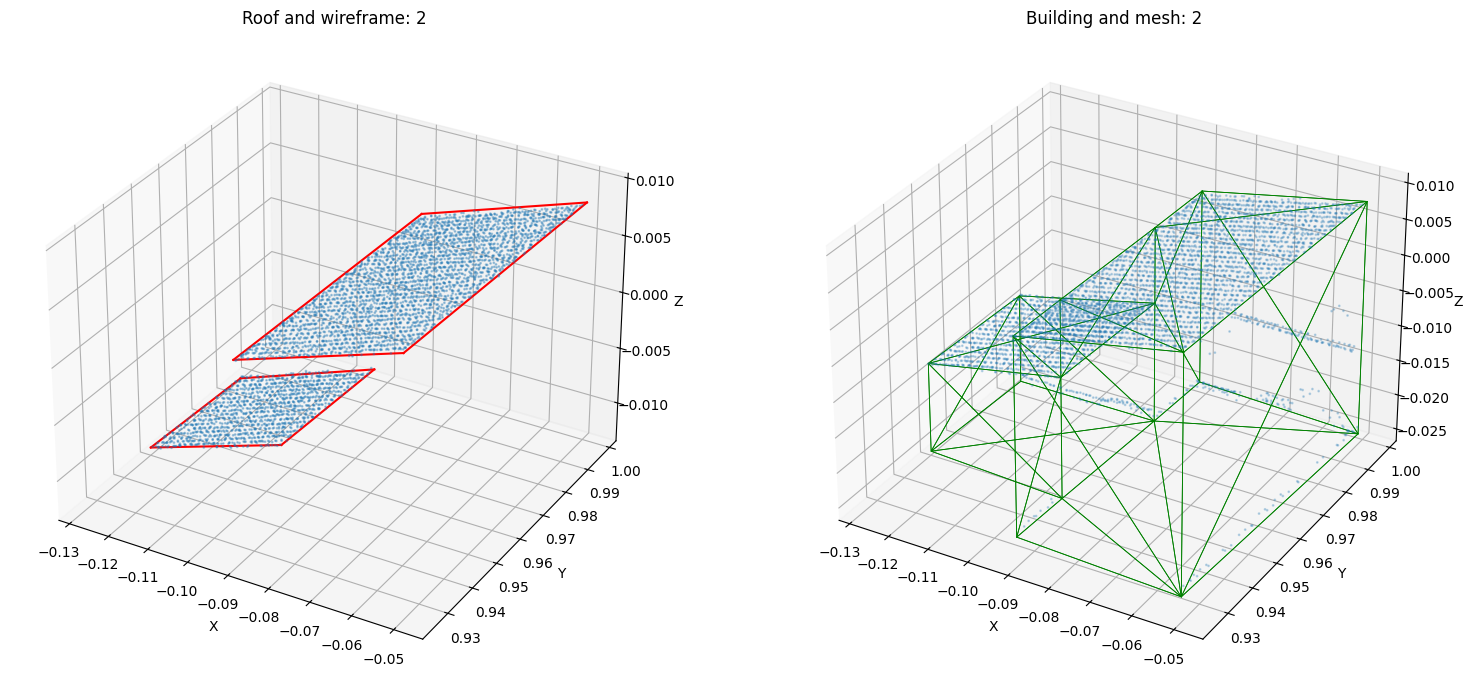

In [21]:
random_generator = np.random.default_rng(
    42
)

building_xyz = loaded_sample[
    "building"
][:, :3]

roof_xyz = loaded_sample[
    "roof"
][:, :3]

wireframe_vertices = loaded_sample[
    "wireframe_vertices"
]

wireframe_edges = loaded_sample[
    "wireframe_edges"
]

mesh_vertices = loaded_sample[
    "mesh_vertices"
]

mesh_faces = loaded_sample[
    "mesh_faces"
]

building_sample_indices = random_generator.choice(
    len(building_xyz),
    size=min(
        20000,
        len(building_xyz)
    ),
    replace=False
)

roof_sample_indices = random_generator.choice(
    len(roof_xyz),
    size=min(
        20000,
        len(roof_xyz)
    ),
    replace=False
)

figure = plt.figure(
    figsize=(16, 7)
)

wireframe_axis = figure.add_subplot(
    121,
    projection="3d"
)

wireframe_axis.scatter(
    roof_xyz[roof_sample_indices, 0],
    roof_xyz[roof_sample_indices, 1],
    roof_xyz[roof_sample_indices, 2],
    s=1,
    alpha=0.35
)

for edge in wireframe_edges:
    edge_segment = wireframe_vertices[
        edge
    ]

    wireframe_axis.plot(
        edge_segment[:, 0],
        edge_segment[:, 1],
        edge_segment[:, 2],
        color="red",
        linewidth=1.5
    )

wireframe_axis.set_title(
    f"Roof and wireframe: {loaded_sample['building_id']}"
)

mesh_axis = figure.add_subplot(
    122,
    projection="3d"
)

mesh_axis.scatter(
    building_xyz[building_sample_indices, 0],
    building_xyz[building_sample_indices, 1],
    building_xyz[building_sample_indices, 2],
    s=1,
    alpha=0.25
)

for face in mesh_faces[:3000]:
    face_polygon = mesh_vertices[
        face
    ]

    closed_polygon = np.vstack([
        face_polygon,
        face_polygon[0]
    ])

    mesh_axis.plot(
        closed_polygon[:, 0],
        closed_polygon[:, 1],
        closed_polygon[:, 2],
        color="green",
        linewidth=0.6
    )

mesh_axis.set_title(
    f"Building and mesh: {loaded_sample['building_id']}"
)

for plot_axis in [
    wireframe_axis,
    mesh_axis
]:
    plot_axis.set_xlabel("X")
    plot_axis.set_ylabel("Y")
    plot_axis.set_zlabel("Z")

plt.tight_layout()
plt.show()

In [22]:
train_ids = set(
    valid_core_manifest.loc[
        valid_core_manifest["project_split"] == "train",
        "building_id"
    ].astype(str)
)

validation_ids = set(
    valid_core_manifest.loc[
        valid_core_manifest["project_split"] == "val",
        "building_id"
    ].astype(str)
)

test_ids = set(
    valid_core_manifest.loc[
        valid_core_manifest["project_split"] == "test",
        "building_id"
    ].astype(str)
)

all_valid_ids = set(
    valid_core_manifest[
        "building_id"
    ].astype(str)
)

assert train_ids
assert validation_ids
assert test_ids
assert train_ids.isdisjoint(validation_ids)
assert train_ids.isdisjoint(test_ids)
assert validation_ids.isdisjoint(test_ids)
assert train_ids | validation_ids | test_ids == all_valid_ids

required_output_paths = [
    PHASE1_DIR / "manifest_all.csv",
    PHASE1_DIR / "manifest_core_valid.csv",
    PHASE1_DIR / "manifest_structural_valid.csv",
    PHASE1_DIR / "invalid_samples.csv",
    PHASE1_DIR / "quality_metadata.csv",
    PHASE1_DIR / "train_ids.txt",
    PHASE1_DIR / "val_ids.txt",
    PHASE1_DIR / "test_ids.txt",
    PHASE1_DIR / "preprocessing_config.json",
    PHASE1_DIR / "dataset_summary.json"
]

for required_path in required_output_paths:
    assert required_path.exists()
    assert required_path.stat().st_size > 0

for archive_path in ARCHIVES.values():
    assert archive_path.exists()
    assert zipfile.is_zipfile(archive_path)

print("Train buildings:", len(train_ids))
print("Validation buildings:", len(validation_ids))
print("Test buildings:", len(test_ids))
print("No split overlap detected.")
print("All archives are valid ZIP files.")
print("All required Phase 1 outputs exist.")
print("Building3D Tallinn Phase 1 is complete.")
print("Output directory:", PHASE1_DIR)

Train buildings: 36819
Validation buildings: 4645
Test buildings: 4659
No split overlap detected.
All archives are valid ZIP files.
All required Phase 1 outputs exist.
Building3D Tallinn Phase 1 is complete.
Output directory: /kaggle/working/building3d_tallinn/phase1_outputs
